# Correlation of the landmark features with the rent

Spearman correlation between each railway-station and school feature and the **monthly rent normalised by the monthly trend**: the rent of a rental divided by the mean rent of its approval month, so that the rise of rents over 2021-2024 does not show up as a spurious correlation.
Train rows only (2021-01..2024-03). Stations with no traffic data and schools with no published cut-off are stored as `-1` in the feature table; those rentals are left out of the correlation of the feature concerned.
For the cut-offs a **lower score means a more selective school**, so a negative correlation means higher rents near more selective schools.

In [1]:
import sys
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import Patch


def find_root(start):
    """final_report: the folder that holds data/feature_config_static.py."""
    for folder in (start, *start.parents):
        if (folder / 'data' / 'feature_config_static.py').exists():
            return folder
    raise FileNotFoundError('final_report/data/feature_config_static.py not found above ' + str(start))


ROOT = find_root(Path.cwd().resolve())
sys.path.insert(0, str(ROOT))
from data.feature_config_static import LABEL, NUMERICAL_COL      # noqa: E402

FINAL = ROOT / 'data' / 'features' / 'final'
LANDMARKS = {                                                      # feature: (label, group)
    'nearest_station_m': ('Distance to the nearest station', 'Railway stations'),
    'n_stations_500m': ('Stations within 500 m', 'Railway stations'),
    'n_stations_1000m': ('Stations within 1,000 m', 'Railway stations'),
    'mrt_traffic_total_tap_norm': ('Traffic of the nearest station', 'Railway stations'),
    'train_lines': ('Train lines at the nearest station', 'Railway stations'),
    'nearest_school_m': ('Distance to the nearest school (any level)', 'Schools'),
    'nearest_pri_school_m': ('Distance to the nearest primary school', 'Schools'),
    'nearest_sec_school_m': ('Distance to the nearest secondary school', 'Schools'),
    'nearest_jc_school_m': ('Distance to the nearest junior college', 'Schools'),
    'sec_sch_score_entry_min': ('Secondary school cut-off, lower bound', 'Schools'),
    'sec_sch_score_entry_max': ('Secondary school cut-off, upper bound', 'Schools'),
    'jc_arts_entry_min': ('Junior college cut-off (arts), lower bound', 'Schools'),
    'jc_arts_entry_max': ('Junior college cut-off (arts), upper bound', 'Schools'),
    'jc_science_entry_min': ('Junior college cut-off (science), lower bound', 'Schools'),
    'jc_science_entry_max': ('Junior college cut-off (science), upper bound', 'Schools'),
}
NO_DATA = ['mrt_traffic_total_tap_norm', 'sec_sch_score_entry_min', 'sec_sch_score_entry_max', 'jc_arts_entry_min', 'jc_arts_entry_max', 'jc_science_entry_min', 'jc_science_entry_max']

static = pd.read_csv(FINAL / 'static_train_scaled.csv')
train = static[static['sample_type'] == 'train'].reset_index(drop=True)
month = (train['RENT_APPROVAL_YEAR'] - 2021) * 12 + train['RENT_APPROVAL_MONTH'] - 1
train['rent_vs_month'] = train[LABEL] / train.groupby(month)[LABEL].transform('mean')

scaler = joblib.load(FINAL / 'scalers' / 'static_numerical_scalers.pkl')       # back to the original units to find the -1 markers
assert list(scaler.feature_names_in_) == NUMERICAL_COL
raw = pd.DataFrame(scaler.inverse_transform(train[NUMERICAL_COL]), columns=NUMERICAL_COL)
raw['train_lines'] = train['train_lines'].to_numpy()

rows = []
for feature, (label, group) in LANDMARKS.items():
    keep = ~(raw[feature].round(3) == -1) if feature in NO_DATA else np.ones(len(raw), dtype=bool)
    rows.append({'feature': feature, 'label': label, 'group': group, 'spearman': raw.loc[keep, feature].corr(train.loc[keep, 'rent_vs_month'], method='spearman'), 'rentals': int(keep.sum())})
corr = pd.DataFrame(rows).set_index('feature').sort_values('spearman')
display(corr[['group', 'spearman', 'rentals']].round(3))

,group,spearman,rentals
feature,,,
nearest_station_m,Railway stations,-0.113,114841
jc_science_entry_min,Schools,-0.083,94887
jc_arts_entry_max,Schools,-0.083,94887
jc_science_entry_max,Schools,-0.068,94887
sec_sch_score_entry_min,Schools,-0.035,108490
jc_arts_entry_min,Schools,-0.027,94887
nearest_pri_school_m,Schools,-0.010,114841
nearest_school_m,Schools,-0.009,114841
mrt_traffic_total_tap_norm,Railway stations,0.000,97172


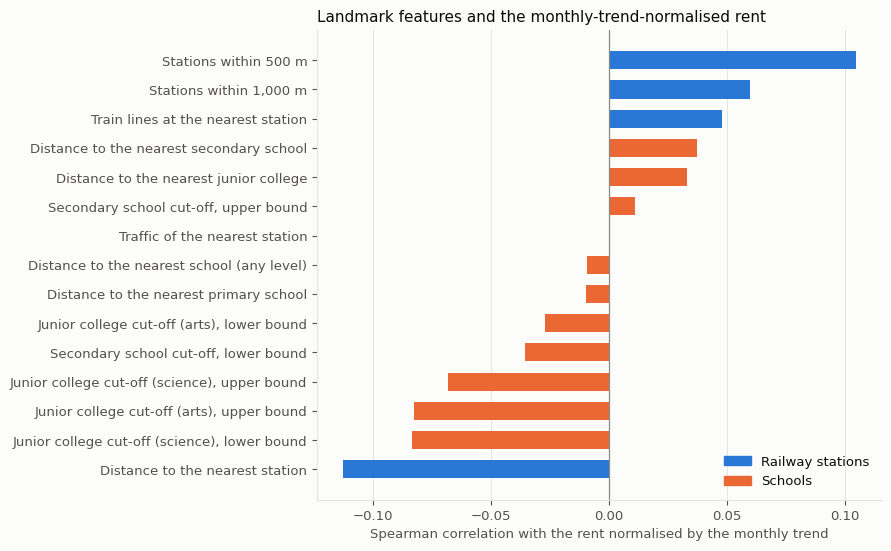

In [2]:
INK, INK2, MUTED, GRID, SURFACE = '#0b0b0b', '#52514e', '#8a8984', '#e6e5e1', '#fcfcfb'
COLOUR = {'Railway stations': '#2a78d6', 'Schools': '#eb6834'}
plt.rcParams.update({'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'axes.edgecolor': GRID, 'axes.labelcolor': INK2, 'axes.titlecolor': INK, 'axes.titlesize': 11, 'axes.titleweight': 'normal',
                     'axes.titlelocation': 'left', 'axes.spines.top': False, 'axes.spines.right': False, 'axes.grid': True, 'grid.color': GRID, 'grid.linewidth': 0.7, 'axes.axisbelow': True,
                     'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK, 'font.size': 9.5, 'legend.frameon': False})

fig, ax = plt.subplots(figsize=(9, 5.6))
pos = np.arange(len(corr))
ax.barh(pos, corr['spearman'], color=[COLOUR[g] for g in corr['group']], height=0.62)
ax.axvline(0, color=MUTED, lw=0.9)
ax.set_yticks(pos, corr['label'])
ax.grid(axis='y', visible=False)
ax.set_xlabel('Spearman correlation with the rent normalised by the monthly trend')
ax.set_title('Landmark features and the monthly-trend-normalised rent')
ax.legend(handles=[Patch(color=c, label=g) for g, c in COLOUR.items()], loc='lower right')
plt.tight_layout()
plt.show()

# Correlation of the flat features with the rent

The same chart for the features of the flat itself: floor area, highest floor of the block, flat type and flat model, against the rent normalised by the monthly trend (Spearman correlation, train rows).
A flat type or model is a 0/1 feature, so its bar says whether flats of that type rent above (positive) or below (negative) the market of their month. The share of the train rentals that have it is in brackets.
Flat types and models with fewer than 100 train rentals are left out: with so few rentals their correlation is not reliable.

In [3]:
from data.feature_config_static import HOT_COL            # noqa: E402

MIN_RENTALS = 100
flat_features = ['FLOOR_AREA_SQM', 'MAX_FLOOR'] + [c for c in HOT_COL if c.startswith('FLAT_')]
rows = []
for feature in flat_features:
    count = int(train[feature].sum()) if feature in HOT_COL else len(train)
    if count < MIN_RENTALS:
        continue
    if feature == 'FLOOR_AREA_SQM':
        label, group = 'Floor area (sqm)', 'Size and height'
    elif feature == 'MAX_FLOOR':
        label, group = 'Highest floor of the block', 'Size and height'
    else:
        kind, name = ('type', feature[len('FLAT_TYPE_'):]) if feature.startswith('FLAT_TYPE_') else ('model', feature[len('FLAT_MODEL_'):])
        label, group = f'Flat {kind}: {name} ({count / len(train):.1%})', f'Flat {kind}'
    rows.append({'feature': feature, 'label': label, 'group': group, 'spearman': train[feature].corr(train['rent_vs_month'], method='spearman'), 'rentals': count})
flat_corr = pd.DataFrame(rows).set_index('feature').sort_values('spearman')
omitted = [f for f in flat_features if f not in flat_corr.index]
print(f'{len(flat_corr)} flat features shown; left out for having fewer than {MIN_RENTALS} train rentals: {omitted}')
display(flat_corr[['group', 'spearman', 'rentals']].round(3))

21 flat features shown; left out for having fewer than 100 train rentals: ['FLAT_TYPE_1 room', 'FLAT_MODEL_2 room', 'FLAT_MODEL_3gen', 'FLAT_MODEL_improved maisonette', 'FLAT_MODEL_premium apartment loft', 'FLAT_MODEL_premium maisonette', 'FLAT_MODEL_terrace']


,group,spearman,rentals
feature,,,
FLAT_TYPE_3 room,Flat type,-0.389,37413
FLAT_MODEL_new generation,Flat model,-0.181,21007
FLAT_TYPE_2 room,Flat type,-0.172,2157
FLAT_MODEL_standard,Flat model,-0.060,4560
FLAT_MODEL_simplified,Flat model,-0.045,5227
FLAT_MODEL_model a2,Flat model,-0.023,1190
FLAT_MODEL_model a,Flat model,0.019,32320
FLAT_MODEL_model a maisonette,Flat model,0.027,109
FLAT_MODEL_adjoined flat,Flat model,0.030,171


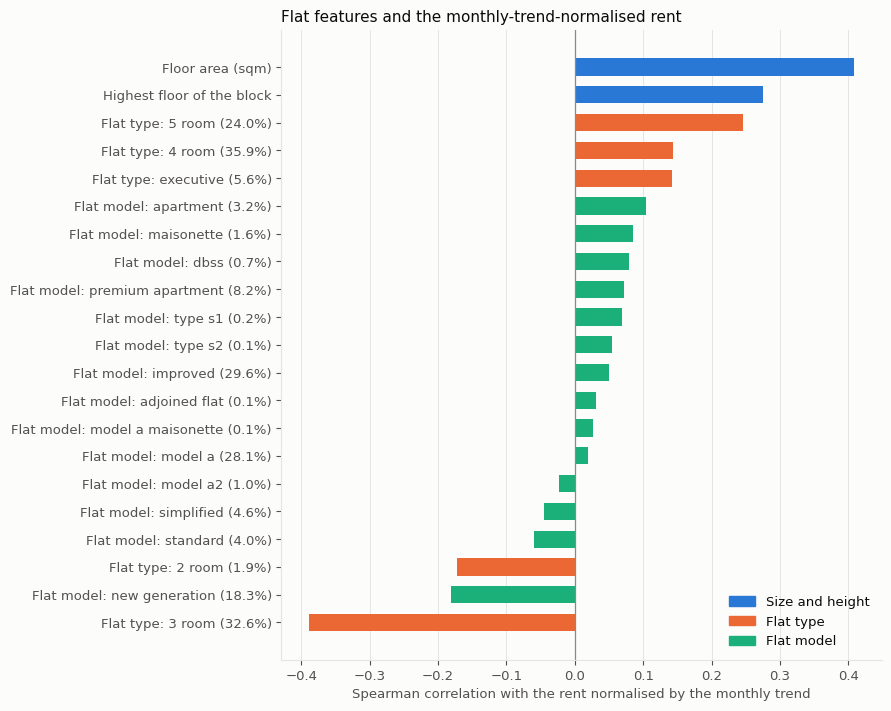

In [4]:
FLAT_COLOUR = {'Size and height': '#2a78d6', 'Flat type': '#eb6834', 'Flat model': '#1baf7a'}
fig, ax = plt.subplots(figsize=(9, 7.2))
pos = np.arange(len(flat_corr))
ax.barh(pos, flat_corr['spearman'], color=[FLAT_COLOUR[g] for g in flat_corr['group']], height=0.62)
ax.axvline(0, color=MUTED, lw=0.9)
ax.set_yticks(pos, flat_corr['label'])
ax.grid(axis='y', visible=False)
ax.set_xlabel('Spearman correlation with the rent normalised by the monthly trend')
ax.set_title('Flat features and the monthly-trend-normalised rent')
ax.legend(handles=[Patch(color=c, label=g) for g, c in FLAT_COLOUR.items()], loc='lower right')
plt.tight_layout()
plt.show()